# TARGET_3.CSV — FDIA Impact Figures
Generates **9 publication figures** from a single run.

### Steps
1. Set `CSV_PATH` to your file
2. Press **Shift + Enter**
3. All PNG + PDF files saved in the same folder

| Fig | Content |
|---|---|
| 1 | Energy served over time |
| 2 | Energy ratio bar summary |
| 3 | Loads served & shed hourly |
| 4 | Switch & load changes due to FDIA |
| 5 | Voltage violation hourly |
| 6 | Voltage min & max hourly |
| 7 | Physical impact score distribution |
| 8 | Detection rate by detector |
| 9 | Action changed per hour |


Loaded 720 rows | Methods: ['GRL', 'MLP', 'BPSO'] | Hours: 0-23

Fig 1: Energy Served Over Time...
  Saved: fig1_energy_served_hourly.png
  Saved: fig1_energy_served_hourly.pdf


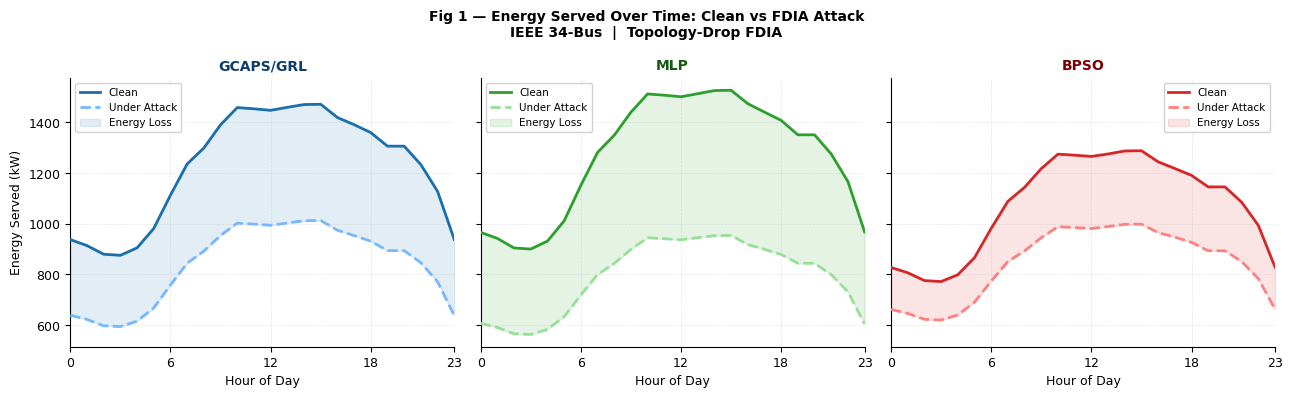


Fig 2: Energy Ratio Bar...
  Saved: fig2_energy_ratio_bar.png
  Saved: fig2_energy_ratio_bar.pdf


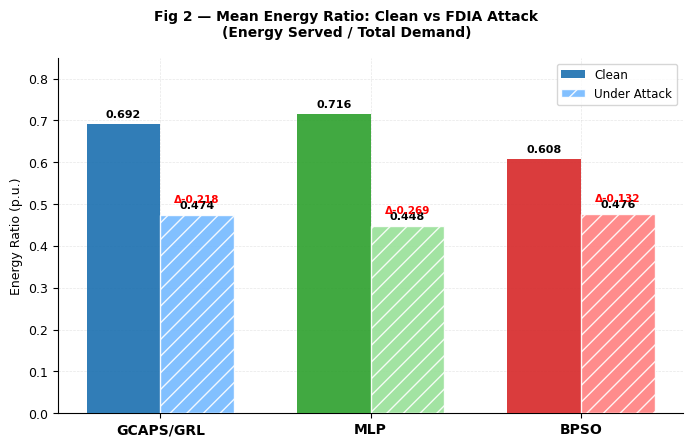


Fig 3: Loads Served & Shed...
  Saved: fig3_loads_served_shed_hourly.png
  Saved: fig3_loads_served_shed_hourly.pdf


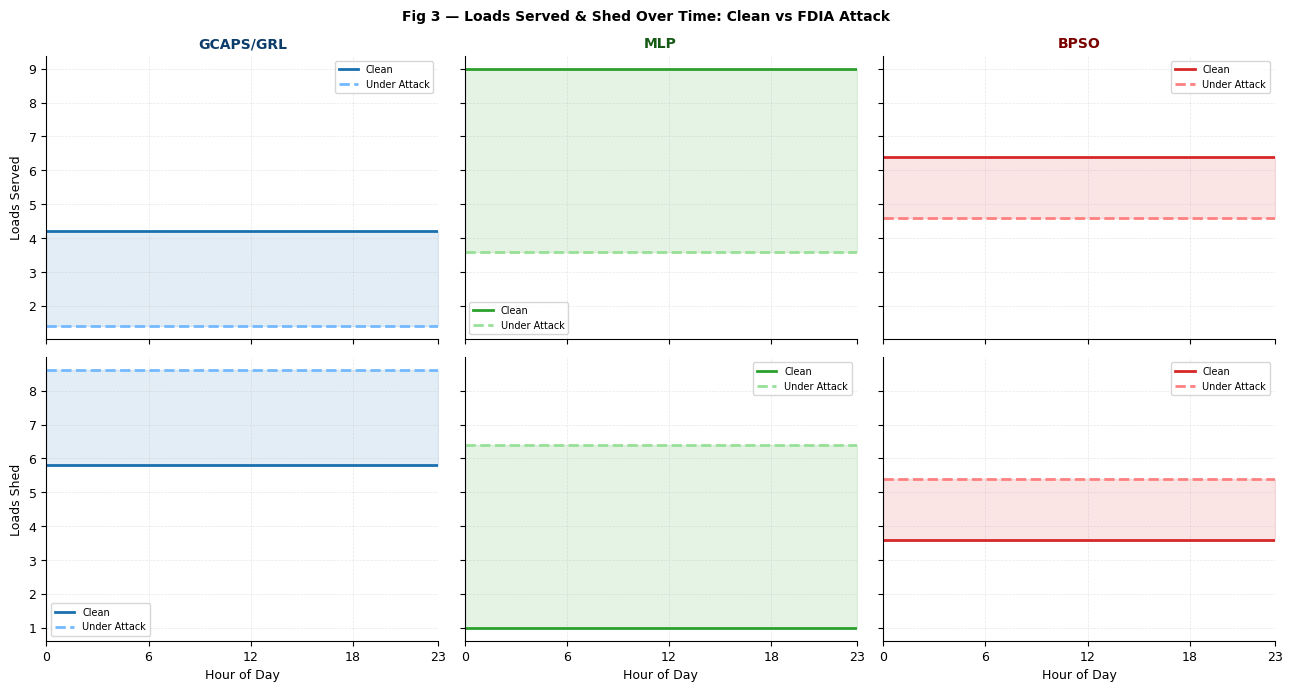


Fig 4: Switch & Load Changes...
  Saved: fig4_switch_load_changes.png
  Saved: fig4_switch_load_changes.pdf


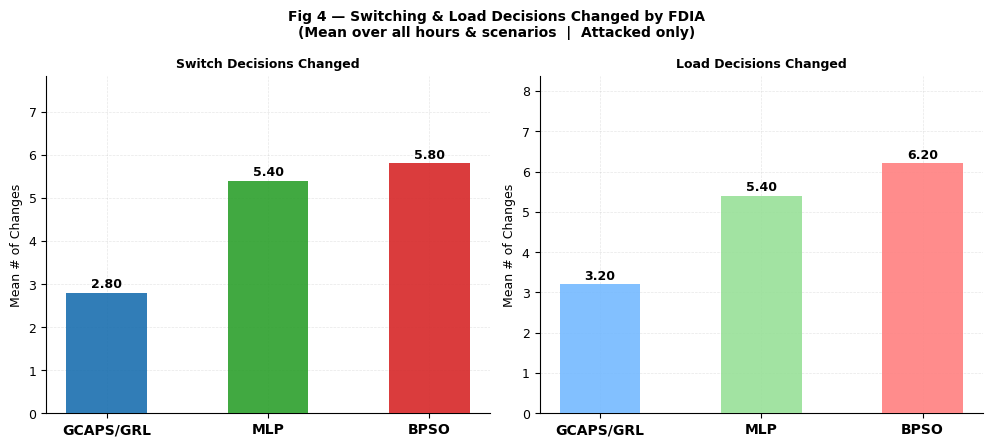


Fig 5: Voltage Violation...
  Saved: fig5_voltage_violation_hourly.png
  Saved: fig5_voltage_violation_hourly.pdf


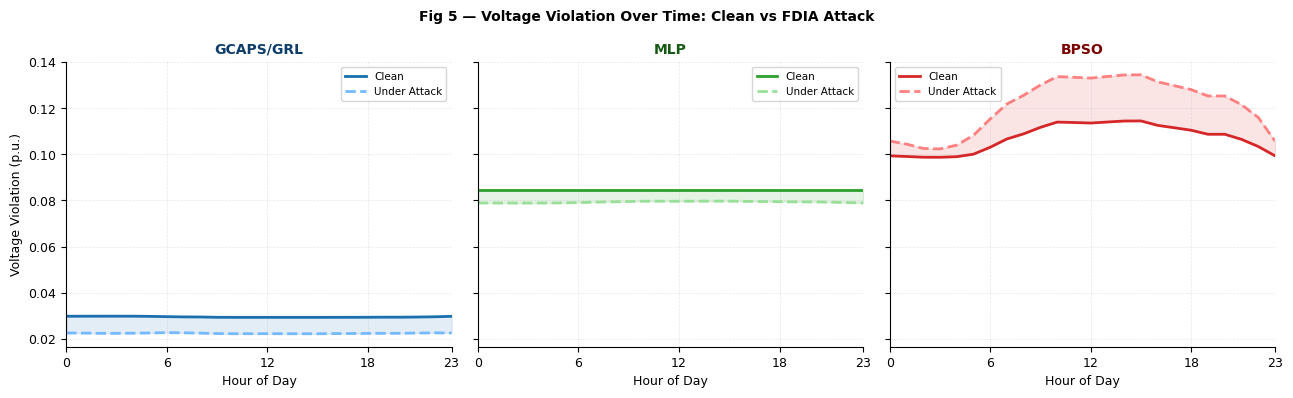


Fig 6: Voltage Min & Max...
  Saved: fig6_voltage_min_max_hourly.png
  Saved: fig6_voltage_min_max_hourly.pdf


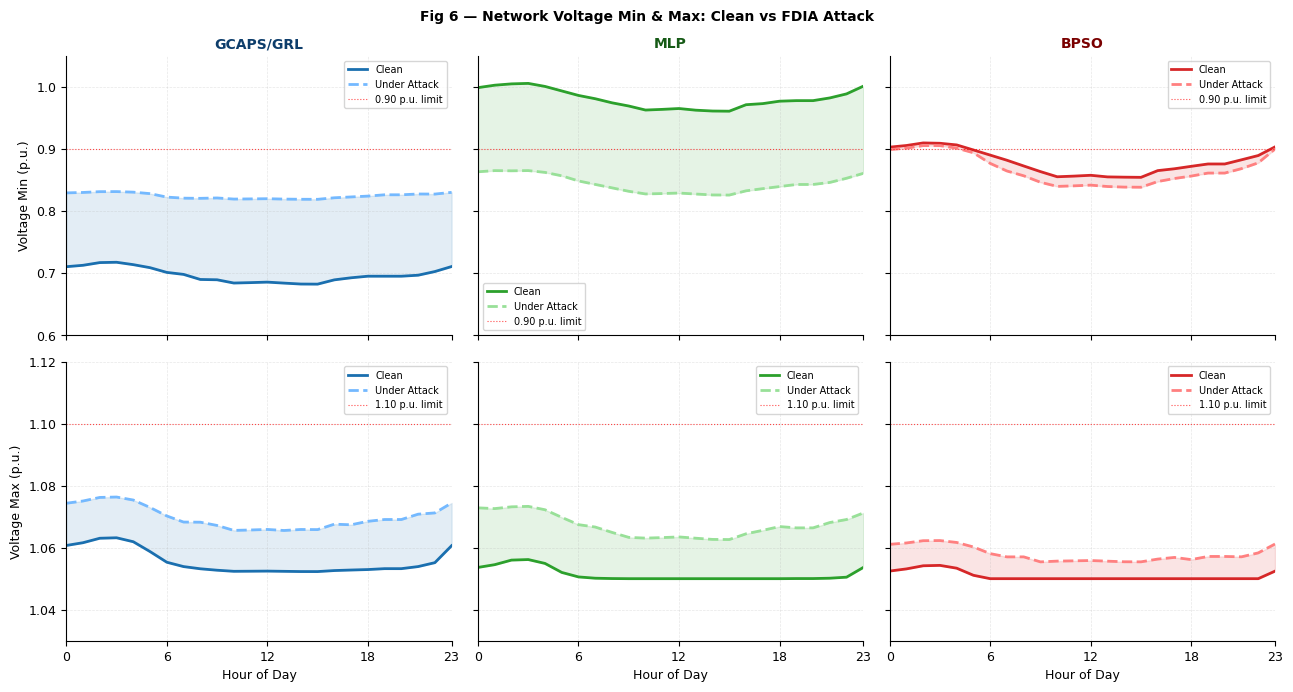


Fig 7: Physical Impact Score...
  Saved: fig7_physical_impact_score.png
  Saved: fig7_physical_impact_score.pdf


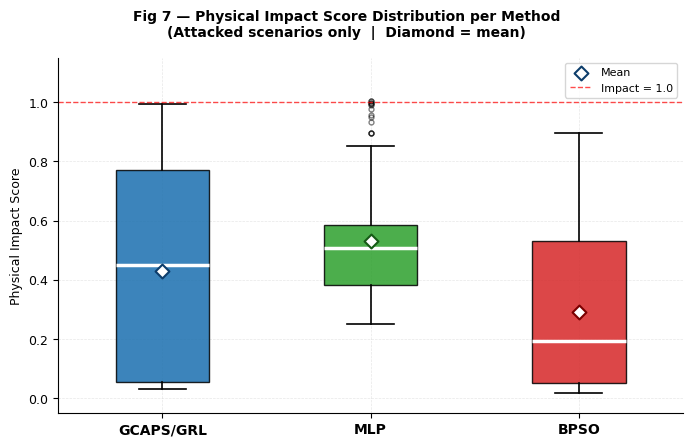


Fig 8: Detection Results...
  Saved: fig8_detection_results.png
  Saved: fig8_detection_results.pdf


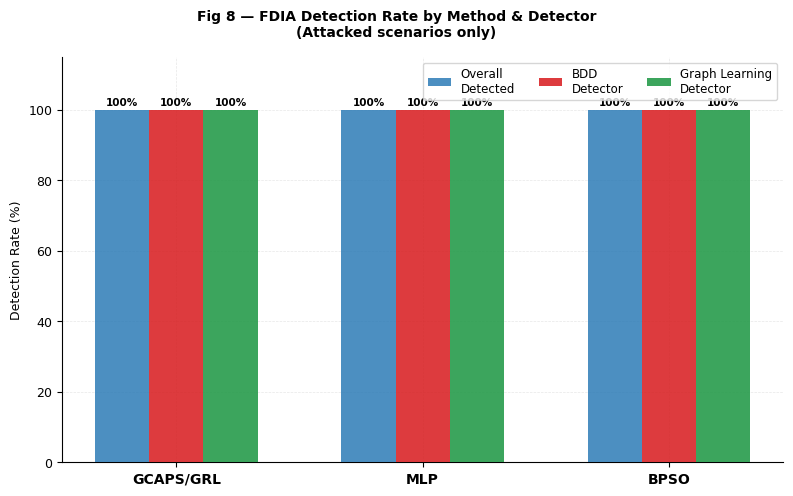


Fig 9: Action Changed...
  Saved: fig9_action_changed_hourly.png
  Saved: fig9_action_changed_hourly.pdf


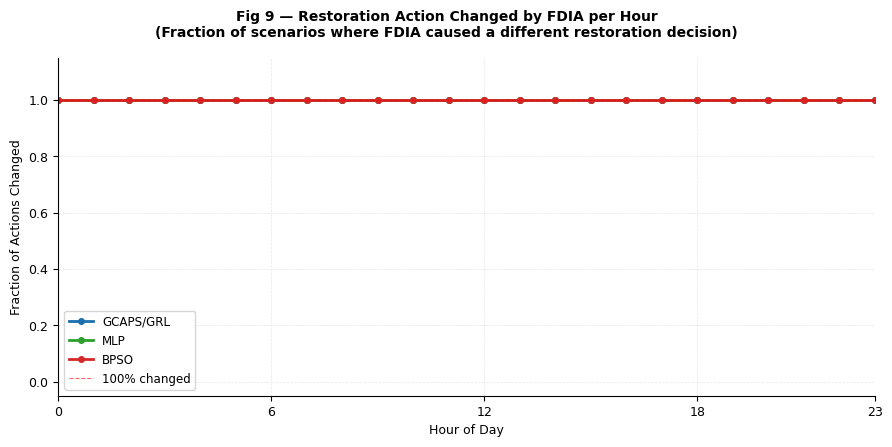


=== All 9 figures done! ===


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib.patches import Patch
import warnings
warnings.filterwarnings('ignore')
%matplotlib inline

# ================================================================
# USER SETTINGS
# ================================================================
CSV_PATH = r'C:\Users\ISLAS2\Downloads\targeted_method_comparison_34bus.CSV'   # <-- your path
SAVE_PNG = True
SAVE_PDF = True
# ================================================================

df = pd.read_csv(CSV_PATH)
print(f'Loaded {len(df):,} rows | Methods: {df["method"].unique().tolist()} | Hours: 0-{df["hour"].max()}')

METHODS = ['GRL', 'MLP', 'BPSO']
LABELS  = {'GRL':'GCAPS/GRL', 'MLP':'MLP', 'BPSO':'BPSO'}
C_CLEAN = {'GRL':'#1a6faf', 'MLP':'#2ca02c', 'BPSO':'#d62728'}
C_ATK   = {'GRL':'#74b9ff', 'MLP':'#98e098', 'BPSO':'#ff8080'}
C_DARK  = {'GRL':'#0d3d6b', 'MLP':'#165a16', 'BPSO':'#7a0000'}
hours   = np.arange(24)

plt.rcParams.update({
    'font.family':'DejaVu Sans', 'font.size':9,
    'axes.spines.top':False, 'axes.spines.right':False,
    'axes.linewidth':0.8, 'axes.grid':True,
    'grid.alpha':0.3, 'grid.linestyle':'--', 'grid.linewidth':0.5,
    'xtick.direction':'out', 'ytick.direction':'out',
    'figure.facecolor':'white',
})

def save_fig(fig, name):
    if SAVE_PNG:
        fig.savefig(f'{name}.png', bbox_inches='tight', dpi=200)
        print(f'  Saved: {name}.png')
    if SAVE_PDF:
        fig.savefig(f'{name}.pdf', bbox_inches='tight', dpi=200)
        print(f'  Saved: {name}.pdf')

# ================================================================
# FIG 1 — Energy served over time
# ================================================================
print('\nFig 1: Energy Served Over Time...')
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
fig.suptitle('Fig 1 — Energy Served Over Time: Clean vs FDIA Attack\nIEEE 34-Bus  |  Topology-Drop FDIA',
             fontsize=10, fontweight='bold')
for ax, m in zip(axes, METHODS):
    c = df[(df['method']==m)&(df['mode']=='clean_dynamic')   ].groupby('hour')['energy_kw'].mean()
    a = df[(df['method']==m)&(df['mode']=='attacked_dynamic')].groupby('hour')['energy_kw'].mean()
    ax.plot(hours, c.values, color=C_CLEAN[m], lw=2, label='Clean', zorder=3)
    ax.plot(hours, a.values, color=C_ATK[m],   lw=2, ls='--', label='Under Attack', zorder=3)
    ax.fill_between(hours, c.values, a.values, color=C_CLEAN[m], alpha=0.12, label='Energy Loss')
    ax.set_title(LABELS[m], fontsize=10, fontweight='bold', color=C_DARK[m])
    ax.set_xlabel('Hour of Day'); ax.set_xlim(0,23); ax.set_xticks([0,6,12,18,23])
    ax.legend(fontsize=7.5, framealpha=0.9)
axes[0].set_ylabel('Energy Served (kW)', fontsize=9)
plt.tight_layout()
save_fig(fig, 'fig1_energy_served_hourly')
plt.show()

# ================================================================
# FIG 2 — Energy ratio bar summary
# ================================================================
print('\nFig 2: Energy Ratio Bar...')
fig, ax = plt.subplots(figsize=(7, 4.5))
fig.suptitle('Fig 2 — Mean Energy Ratio: Clean vs FDIA Attack\n(Energy Served / Total Demand)',
             fontsize=10, fontweight='bold')
x = np.arange(len(METHODS)); w = 0.35
cv = [df[(df['method']==m)&(df['mode']=='clean_dynamic')   ]['energy_ratio'].mean() for m in METHODS]
av = [df[(df['method']==m)&(df['mode']=='attacked_dynamic')]['energy_ratio'].mean() for m in METHODS]
b1 = ax.bar(x-w/2, cv, w, color=[C_CLEAN[m] for m in METHODS], label='Clean',        alpha=0.9, zorder=3)
b2 = ax.bar(x+w/2, av, w, color=[C_ATK[m]   for m in METHODS], label='Under Attack',  alpha=0.9, hatch='//', zorder=3, edgecolor='white')
for bar in list(b1)+list(b2):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.01,
            f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=8, fontweight='bold')
for i,m in enumerate(METHODS):
    ax.annotate(f'\u0394{av[i]-cv[i]:.3f}', xy=(i+w/2, av[i]+0.03),
                ha='center', fontsize=7.5, color='red', fontweight='bold')
ax.set_xticks(x); ax.set_xticklabels([LABELS[m] for m in METHODS], fontsize=10, fontweight='bold')
ax.set_ylabel('Energy Ratio (p.u.)'); ax.set_ylim(0, 0.85); ax.legend(fontsize=8.5)
plt.tight_layout()
save_fig(fig, 'fig2_energy_ratio_bar')
plt.show()

# ================================================================
# FIG 3 — Loads served & shed hourly
# ================================================================
print('\nFig 3: Loads Served & Shed...')
fig, axes = plt.subplots(2, 3, figsize=(13, 7), sharey='row', sharex=True)
fig.suptitle('Fig 3 — Loads Served & Shed Over Time: Clean vs FDIA Attack',
             fontsize=10, fontweight='bold')
for col_i, m in enumerate(METHODS):
    for row_i, (col, ylabel) in enumerate([('loads_served','Loads Served'),('loads_shed','Loads Shed')]):
        ax = axes[row_i][col_i]
        c = df[(df['method']==m)&(df['mode']=='clean_dynamic')   ].groupby('hour')[col].mean()
        a = df[(df['method']==m)&(df['mode']=='attacked_dynamic')].groupby('hour')[col].mean()
        ax.plot(hours, c.values, color=C_CLEAN[m], lw=2, label='Clean')
        ax.plot(hours, a.values, color=C_ATK[m],   lw=2, ls='--', label='Under Attack')
        ax.fill_between(hours, c.values, a.values, color=C_CLEAN[m], alpha=0.12)
        if row_i==0: ax.set_title(LABELS[m], fontsize=10, fontweight='bold', color=C_DARK[m])
        if row_i==1: ax.set_xlabel('Hour of Day')
        if col_i==0: ax.set_ylabel(ylabel, fontsize=9)
        ax.set_xlim(0,23); ax.set_xticks([0,6,12,18,23]); ax.legend(fontsize=7)
plt.tight_layout()
save_fig(fig, 'fig3_loads_served_shed_hourly')
plt.show()

# ================================================================
# FIG 4 — Switch & load changes
# ================================================================
print('\nFig 4: Switch & Load Changes...')
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
fig.suptitle('Fig 4 — Switching & Load Decisions Changed by FDIA\n(Mean over all hours & scenarios  |  Attacked only)',
             fontsize=10, fontweight='bold')
atk = df[df['mode']=='attacked_dynamic']
x   = np.arange(len(METHODS))
for ax, col, title, ck in [
    (axes[0], 'switch_changes_vs_clean', 'Switch Decisions Changed', C_CLEAN),
    (axes[1], 'load_changes_vs_clean',   'Load Decisions Changed',   C_ATK),
]:
    vals = [atk[atk['method']==m][col].mean() for m in METHODS]
    bars = ax.bar(x, vals, color=[ck[m] for m in METHODS], alpha=0.9, width=0.5, zorder=3)
    for bar in bars:
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.05,
                f'{bar.get_height():.2f}', ha='center', va='bottom', fontsize=9, fontweight='bold')
    ax.set_xticks(x); ax.set_xticklabels([LABELS[m] for m in METHODS], fontsize=10, fontweight='bold')
    ax.set_ylabel('Mean # of Changes'); ax.set_title(title, fontsize=9, fontweight='bold')
    ax.set_ylim(0, max(vals)*1.35)
plt.tight_layout()
save_fig(fig, 'fig4_switch_load_changes')
plt.show()

# ================================================================
# FIG 5 — Voltage violation hourly
# ================================================================
print('\nFig 5: Voltage Violation...')
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
fig.suptitle('Fig 5 — Voltage Violation Over Time: Clean vs FDIA Attack',
             fontsize=10, fontweight='bold')
for ax, m in zip(axes, METHODS):
    c = df[(df['method']==m)&(df['mode']=='clean_dynamic')   ].groupby('hour')['voltage_violation'].mean()
    a = df[(df['method']==m)&(df['mode']=='attacked_dynamic')].groupby('hour')['voltage_violation'].mean()
    ax.plot(hours, c.values, color=C_CLEAN[m], lw=2, label='Clean')
    ax.plot(hours, a.values, color=C_ATK[m],   lw=2, ls='--', label='Under Attack')
    ax.fill_between(hours, c.values, a.values, color=C_CLEAN[m], alpha=0.12)
    ax.set_title(LABELS[m], fontsize=10, fontweight='bold', color=C_DARK[m])
    ax.set_xlabel('Hour of Day'); ax.set_xlim(0,23); ax.set_xticks([0,6,12,18,23])
    ax.legend(fontsize=7.5)
axes[0].set_ylabel('Voltage Violation (p.u.)', fontsize=9)
plt.tight_layout()
save_fig(fig, 'fig5_voltage_violation_hourly')
plt.show()

# ================================================================
# FIG 6 — Voltage min & max hourly
# ================================================================
print('\nFig 6: Voltage Min & Max...')
fig, axes = plt.subplots(2, 3, figsize=(13, 7), sharey='row', sharex=True)
fig.suptitle('Fig 6 — Network Voltage Min & Max: Clean vs FDIA Attack',
             fontsize=10, fontweight='bold')
for col_i, m in enumerate(METHODS):
    for row_i, (col, ylabel, lim, hline, hlbl) in enumerate([
        ('voltage_min','Voltage Min (p.u.)',[0.60,1.05], 0.90, '0.90 p.u. limit'),
        ('voltage_max','Voltage Max (p.u.)',[1.03,1.12], 1.10, '1.10 p.u. limit'),
    ]):
        ax = axes[row_i][col_i]
        c  = df[(df['method']==m)&(df['mode']=='clean_dynamic')   ].groupby('hour')[col].mean()
        a  = df[(df['method']==m)&(df['mode']=='attacked_dynamic')].groupby('hour')[col].mean()
        ax.plot(hours, c.values, color=C_CLEAN[m], lw=2, label='Clean')
        ax.plot(hours, a.values, color=C_ATK[m],   lw=2, ls='--', label='Under Attack')
        ax.fill_between(hours, c.values, a.values, color=C_CLEAN[m], alpha=0.12)
        ax.axhline(hline, color='red', lw=0.8, ls=':', alpha=0.7, label=hlbl)
        if row_i==0: ax.set_title(LABELS[m], fontsize=10, fontweight='bold', color=C_DARK[m])
        if row_i==1: ax.set_xlabel('Hour of Day')
        if col_i==0: ax.set_ylabel(ylabel, fontsize=9)
        ax.set_xlim(0,23); ax.set_xticks([0,6,12,18,23]); ax.set_ylim(lim)
        ax.legend(fontsize=7)
plt.tight_layout()
save_fig(fig, 'fig6_voltage_min_max_hourly')
plt.show()

# ================================================================
# FIG 7 — Physical impact score
# ================================================================
print('\nFig 7: Physical Impact Score...')
fig, ax = plt.subplots(figsize=(7, 4.5))
fig.suptitle('Fig 7 — Physical Impact Score Distribution per Method\n(Attacked scenarios only  |  Diamond = mean)',
             fontsize=10, fontweight='bold')
atk  = df[df['mode']=='attacked_dynamic']
data = [atk[atk['method']==m]['physical_impact_score'].values for m in METHODS]
bp   = ax.boxplot(data, positions=[1,2,3], widths=0.45, patch_artist=True,
                  notch=False, showfliers=True,
                  medianprops=dict(color='white', lw=2.5),
                  whiskerprops=dict(lw=1.2), capprops=dict(lw=1.2),
                  flierprops=dict(marker='o', ms=3.5, alpha=0.5))
for patch, m in zip(bp['boxes'], METHODS):
    patch.set_facecolor(C_CLEAN[m]); patch.set_alpha(0.85)
for i, m in enumerate(METHODS):
    ax.scatter(i+1, atk[atk['method']==m]['physical_impact_score'].mean(),
               color='white', s=50, zorder=5, marker='D',
               edgecolors=C_DARK[m], linewidths=1.5, label='Mean' if i==0 else '')
ax.axhline(1.0, color='red', lw=1, ls='--', alpha=0.7, label='Impact = 1.0')
ax.set_xticks([1,2,3]); ax.set_xticklabels([LABELS[m] for m in METHODS], fontsize=10, fontweight='bold')
ax.set_ylabel('Physical Impact Score'); ax.set_ylim(-0.05, 1.15)
ax.legend(fontsize=8)
plt.tight_layout()
save_fig(fig, 'fig7_physical_impact_score')
plt.show()

# ================================================================
# FIG 8 — Detection results
# ================================================================
print('\nFig 8: Detection Results...')
fig, ax = plt.subplots(figsize=(8, 5))
fig.suptitle('Fig 8 — FDIA Detection Rate by Method & Detector\n(Attacked scenarios only)',
             fontsize=10, fontweight='bold')
atk        = df[df['mode']=='attacked_dynamic']
detectors  = ['fdia_detected', 'bdd_detected', 'learning_detected']
det_labels = ['Overall\nDetected', 'BDD\nDetector', 'Graph Learning\nDetector']
det_colors = ['#2c7bb6', '#d7191c', '#1a9641']
x = np.arange(len(METHODS)); w = 0.22; offsets = [-1, 0, 1]
for i, (det, dlbl, dcol) in enumerate(zip(detectors, det_labels, det_colors)):
    vals = [atk[atk['method']==m][det].mean()*100 for m in METHODS]
    bars = ax.bar(x + offsets[i]*w, vals, w, label=dlbl, color=dcol, alpha=0.85, zorder=3)
    for bar in bars:
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.5,
                f'{bar.get_height():.0f}%', ha='center', va='bottom', fontsize=7.5, fontweight='bold')
ax.set_xticks(x); ax.set_xticklabels([LABELS[m] for m in METHODS], fontsize=10, fontweight='bold')
ax.set_ylabel('Detection Rate (%)'); ax.set_ylim(0, 115)
ax.legend(fontsize=8.5, ncol=3)
plt.tight_layout()
save_fig(fig, 'fig8_detection_results')
plt.show()

# ================================================================
# FIG 9 — Action changed per hour
# ================================================================
print('\nFig 9: Action Changed...')
fig, ax = plt.subplots(figsize=(9, 4.5))
fig.suptitle('Fig 9 — Restoration Action Changed by FDIA per Hour\n(Fraction of scenarios where FDIA caused a different restoration decision)',
             fontsize=10, fontweight='bold')
atk = df[df['mode']=='attacked_dynamic']
for m in METHODS:
    vals = atk[atk['method']==m].groupby('hour')['action_changed'].mean()
    ax.plot(hours, vals.values, color=C_CLEAN[m], lw=2, marker='o', ms=4, label=LABELS[m])
ax.axhline(1.0, color='red', lw=0.8, ls='--', alpha=0.6, label='100% changed')
ax.set_xlabel('Hour of Day'); ax.set_ylabel('Fraction of Actions Changed')
ax.set_xlim(0,23); ax.set_xticks([0,6,12,18,23]); ax.set_ylim(-0.05, 1.15)
ax.legend(fontsize=8.5)
plt.tight_layout()
save_fig(fig, 'fig9_action_changed_hourly')
plt.show()

print('\n=== All 9 figures done! ===')


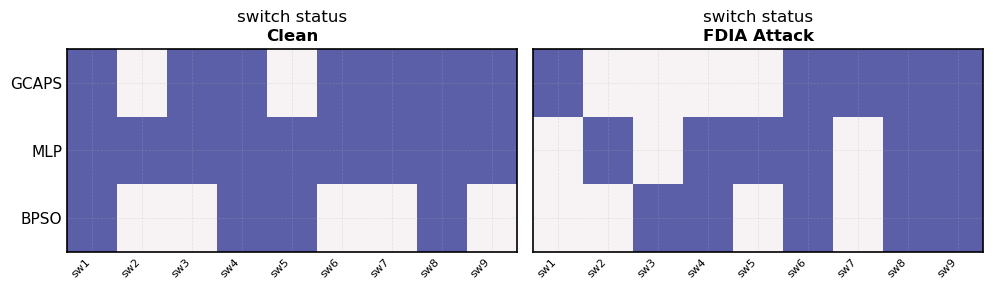

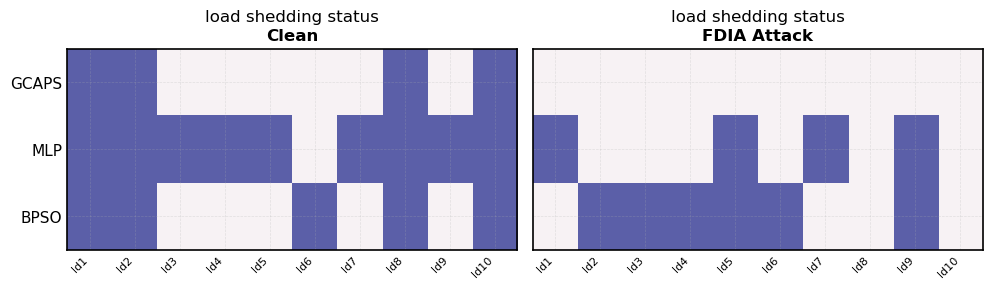

In [5]:
import pandas as pd
import numpy as np
import ast
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

CSV_PATH = r"C:\Users\ISLAS2\Downloads\targeted_method_comparison_34bus.CSV"
df = pd.read_csv(CSV_PATH)

df["method_plot"] = df["method"].replace({"GRL": "GCAPS"})

methods = ["GCAPS", "MLP", "BPSO"]

scenario_map = {
    "Clean": "clean_dynamic",
    "FDIA Attack": "attacked_dynamic"
}

selected_hour = 12
df_hour = df[df["hour"] == selected_hour].copy()


def parse_vector(x):
    """
    Handles:
    [1, 0, 1]
    {'Load.xxx': 1, 'Load.yyy': 0}
    {'Load.xxx': 'served', 'Load.yyy': 'shed'}
    """

    if isinstance(x, str):
        x = ast.literal_eval(x)

    # Important fix: if dictionary, use values only
    if isinstance(x, dict):
        x = list(x.values())

    out = []

    for v in x:
        if isinstance(v, str):
            v_clean = v.strip().lower()

            if v_clean in ["1", "on", "closed", "served", "connected", "energized", "true"]:
                out.append(1)
            elif v_clean in ["0", "off", "open", "shed", "disconnected", "deenergized", "false"]:
                out.append(0)
            else:
                out.append(float(v_clean))
        else:
            out.append(float(v))

    return out


def get_labels(x, prefix):
    """
    Gets labels from dictionary keys if available.
    Otherwise creates sw1, sw2, ...
    """

    if isinstance(x, str):
        x = ast.literal_eval(x)

    if isinstance(x, dict):
        return list(x.keys())

    return [f"{prefix}{i+1}" for i in range(len(x))]


def build_matrix(data, vector_col):
    rows = []
    labels = None

    for method in methods:
        row_df = data[data["method_plot"] == method]

        if row_df.empty:
            raise ValueError(f"No data found for method: {method}")

        raw = row_df.iloc[0][vector_col]

        vec = parse_vector(raw)
        rows.append(vec)

        if labels is None:
            labels = get_labels(raw, "x")

    return np.array(rows, dtype=float), labels


def short_labels(labels, prefix):
    """
    Makes compact labels for plotting.
    """
    return [f"{prefix}{i+1}" for i in range(len(labels))]


def plot_binary_heatmap(vector_col, status_title, output_file, x_prefix):
    fig, axes = plt.subplots(1, 2, figsize=(10, 3), sharey=True)

    cmap = ListedColormap(["#f7f2f4", "#5b5fa8"])

    for ax, (scenario_name, mode_name) in zip(axes, scenario_map.items()):
        data = df_hour[df_hour["mode"] == mode_name]

        matrix, labels = build_matrix(data, vector_col)
        plot_labels = short_labels(labels, x_prefix)

        ax.imshow(matrix, aspect="auto", cmap=cmap, vmin=0, vmax=1)

        ax.set_title(scenario_name, fontsize=12, fontweight="bold")

        ax.set_yticks(np.arange(len(methods)))
        ax.set_yticklabels(methods, fontsize=11)

        ax.set_xticks(np.arange(matrix.shape[1]))
        ax.set_xticklabels(
            plot_labels,
            rotation=45,
            ha="right",
            fontsize=8
        )

        ax.tick_params(axis="both", length=0)

        for spine in ax.spines.values():
            spine.set_visible(True)
            spine.set_linewidth(1.2)

        ax.text(
            0.5,
            1.12,
            status_title,
            transform=ax.transAxes,
            ha="center",
            va="bottom",
            fontsize=12
        )

    plt.tight_layout()
    plt.savefig(output_file, dpi=600, bbox_inches="tight")
    plt.show()


plot_binary_heatmap(
    vector_col="switch_vector",
    status_title="switch status",
    output_file="fig_switch_status_clean_vs_attack.pdf",
    x_prefix="sw"
)

plot_binary_heatmap(
    vector_col="load_status",
    status_title="load shedding status",
    output_file="fig_load_status_clean_vs_attack.pdf",
    x_prefix="ld"
)

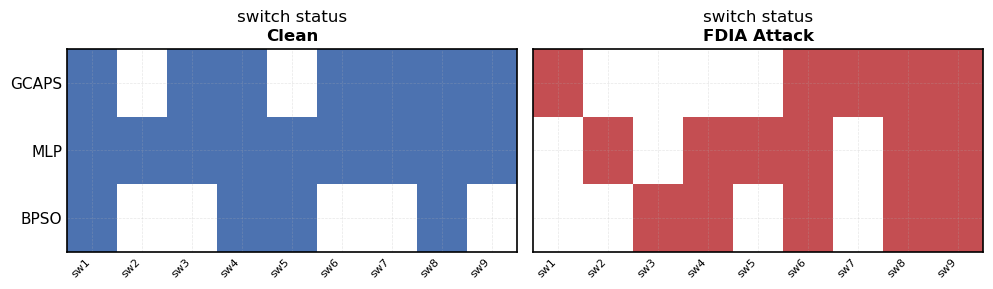

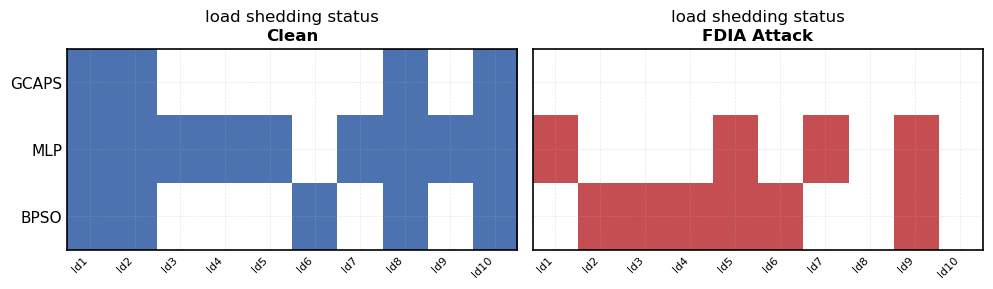

In [7]:
import pandas as pd
import numpy as np
import ast
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

CSV_PATH = r"C:\Users\ISLAS2\Downloads\targeted_method_comparison_34bus.CSV"
df = pd.read_csv(CSV_PATH)

df["method_plot"] = df["method"].replace({"GRL": "GCAPS"})

methods = ["GCAPS", "MLP", "BPSO"]

scenario_map = {
    "Clean": "clean_dynamic",
    "FDIA Attack": "attacked_dynamic"
}

selected_hour = 12
df_hour = df[df["hour"] == selected_hour].copy()


def parse_vector(x):
    if isinstance(x, str):
        x = ast.literal_eval(x)

    if isinstance(x, dict):
        x = list(x.values())

    out = []

    for v in x:
        if isinstance(v, str):
            v_clean = v.strip().lower()

            if v_clean in ["1", "on", "closed", "served", "connected", "energized", "true"]:
                out.append(1)
            elif v_clean in ["0", "off", "open", "shed", "disconnected", "deenergized", "false"]:
                out.append(0)
            else:
                out.append(float(v_clean))
        else:
            out.append(float(v))

    return out


def get_labels(x, prefix):
    if isinstance(x, str):
        x = ast.literal_eval(x)

    if isinstance(x, dict):
        return list(x.keys())

    return [f"{prefix}{i+1}" for i in range(len(x))]


def build_matrix(data, vector_col):
    rows = []
    labels = None

    for method in methods:
        row_df = data[data["method_plot"] == method]

        if row_df.empty:
            raise ValueError(f"No data found for method: {method}")

        raw = row_df.iloc[0][vector_col]
        vec = parse_vector(raw)
        rows.append(vec)

        if labels is None:
            labels = get_labels(raw, "x")

    return np.array(rows, dtype=float), labels


def short_labels(labels, prefix):
    return [f"{prefix}{i+1}" for i in range(len(labels))]


def plot_binary_heatmap(vector_col, status_title, output_file, x_prefix):
    fig, axes = plt.subplots(1, 2, figsize=(10, 3), sharey=True)

    clean_cmap = ListedColormap(["white", "#4C72B0"])   # clean = blue
    attack_cmap = ListedColormap(["white", "#C44E52"])  # attack = red

    for ax, (scenario_name, mode_name) in zip(axes, scenario_map.items()):
        data = df_hour[df_hour["mode"] == mode_name]

        matrix, labels = build_matrix(data, vector_col)
        plot_labels = short_labels(labels, x_prefix)

        if mode_name == "clean_dynamic":
            cmap = clean_cmap
        else:
            cmap = attack_cmap

        ax.imshow(matrix, aspect="auto", cmap=cmap, vmin=0, vmax=1)

        ax.set_title(scenario_name, fontsize=12, fontweight="bold")

        ax.set_yticks(np.arange(len(methods)))
        ax.set_yticklabels(methods, fontsize=11)

        ax.set_xticks(np.arange(matrix.shape[1]))
        ax.set_xticklabels(
            plot_labels,
            rotation=45,
            ha="right",
            fontsize=8
        )

        ax.tick_params(axis="both", length=0)

        for spine in ax.spines.values():
            spine.set_visible(True)
            spine.set_linewidth(1.2)

        ax.text(
            0.5,
            1.12,
            status_title,
            transform=ax.transAxes,
            ha="center",
            va="bottom",
            fontsize=12
        )

    plt.tight_layout()
    plt.savefig(output_file, dpi=600, bbox_inches="tight")
    plt.show()


plot_binary_heatmap(
    vector_col="switch_vector",
    status_title="switch status",
    output_file="fig_switch_status_clean_vs_attack.pdf",
    x_prefix="sw"
)

plot_binary_heatmap(
    vector_col="load_status",
    status_title="load shedding status",
    output_file="fig_load_status_clean_vs_attack.pdf",
    x_prefix="ld"
)

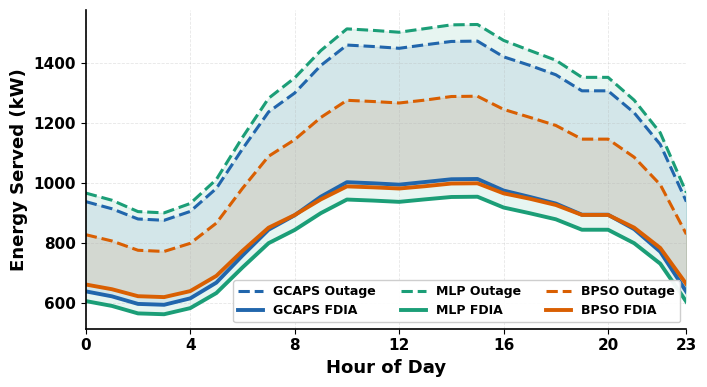

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings("ignore")
%matplotlib inline

CSV_PATH = r"C:\Users\ISLAS2\Downloads\targeted_method_comparison_34bus.CSV"

df = pd.read_csv(CSV_PATH)

METHODS = ["GRL", "MLP", "BPSO"]
LABELS = {
    "GRL": "GCAPS",
    "MLP": "MLP",
    "BPSO": "BPSO"
}

COLORS = {
    "GRL": "#2166ac",
    "MLP": "#1b9e77",
    "BPSO": "#d95f02"
}

hours = np.arange(24)

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.labelweight": "bold",
    "axes.linewidth": 1.2,
    "axes.grid": True,
    "grid.alpha": 0.30,
    "grid.linestyle": "--",
    "grid.linewidth": 0.6,
    "xtick.direction": "out",
    "ytick.direction": "out",
    "figure.facecolor": "white"
})

fig, ax = plt.subplots(figsize=(7.2, 4.0))

for m in METHODS:
    clean = (
        df[(df["method"] == m) & (df["mode"] == "clean_dynamic")]
        .groupby("hour")["energy_kw"]
        .mean()
        .reindex(hours)
    )

    attack = (
        df[(df["method"] == m) & (df["mode"] == "attacked_dynamic")]
        .groupby("hour")["energy_kw"]
        .mean()
        .reindex(hours)
    )

    ax.plot(
        hours,
        clean.values,
        color=COLORS[m],
        linestyle="--",
        linewidth=2.2,
        label=f"{LABELS[m]} Outage"
    )

    ax.plot(
        hours,
        attack.values,
        color=COLORS[m],
        linestyle="-",
        linewidth=2.8,
        label=f"{LABELS[m]} FDIA"
    )

    ax.fill_between(
        hours,
        clean.values,
        attack.values,
        color=COLORS[m],
        alpha=0.10
    )

ax.set_xlabel("Hour of Day", fontsize=13, fontweight="bold")
ax.set_ylabel("Energy Served (kW)", fontsize=13, fontweight="bold")

ax.set_xlim(0, 23)
ax.set_xticks([0, 4, 8, 12, 16, 20, 23])

for tick in ax.get_xticklabels() + ax.get_yticklabels():
    tick.set_fontsize(11)
    tick.set_fontweight("bold")

ax.legend(
    fontsize=9,
    ncol=3,
    loc="best",
    framealpha=0.95,
    prop={"weight": "bold", "size": 9}
)

plt.tight_layout()

fig.savefig("fig1_energy_served_hourly.pdf", dpi=600, bbox_inches="tight")
fig.savefig("fig1_energy_served_hourly.png", dpi=600, bbox_inches="tight")

plt.show()

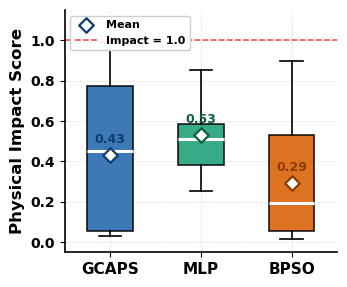

Saved: fig7_physical_impact_score.png
Saved: fig7_physical_impact_score.pdf


In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings("ignore")
%matplotlib inline

# ==========================================================
# USER SETTINGS
# ==========================================================
CSV_PATH = r"C:\Users\ISLAS2\Downloads\targeted_method_comparison_34bus.CSV"

OUTPUT_PNG = "fig7_physical_impact_score.png"
OUTPUT_PDF = "fig7_physical_impact_score.pdf"

SAVE_PNG = True
SAVE_PDF = True

# ==========================================================
# LOAD DATA
# ==========================================================
df = pd.read_csv(CSV_PATH)

METHODS = ["GRL", "MLP", "BPSO"]

LABELS = {
    "GRL": "GCAPS",
    "MLP": "MLP",
    "BPSO": "BPSO"
}

COLORS = {
    "GRL": "#2166ac",
    "MLP": "#1b9e77",
    "BPSO": "#d95f02"
}

EDGE_COLORS = {
    "GRL": "#0b3c6d",
    "MLP": "#0b5d45",
    "BPSO": "#8c3b00"
}

# ==========================================================
# FILTER ATTACKED SCENARIOS ONLY
# ==========================================================
atk = df[df["mode"] == "attacked_dynamic"].copy()

data = [
    atk[atk["method"] == m]["physical_impact_score"].dropna().values
    for m in METHODS
]

# ==========================================================
# STYLE
# ==========================================================
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.linewidth": 1.2,
    "axes.grid": True,
    "grid.alpha": 0.30,
    "grid.linestyle": "--",
    "grid.linewidth": 0.6,
    "xtick.direction": "out",
    "ytick.direction": "out",
    "figure.facecolor": "white"
})

# ==========================================================
# FIGURE
# ==========================================================
fig, ax = plt.subplots(figsize=(3.6, 3.0))

bp = ax.boxplot(
    data,
    positions=np.arange(1, len(METHODS) + 1),
    widths=0.50,
    patch_artist=True,
    showfliers=False,
    medianprops=dict(color="white", linewidth=2.2),
    whiskerprops=dict(linewidth=1.2, color="black"),
    capprops=dict(linewidth=1.2, color="black"),
    boxprops=dict(linewidth=1.2, color="black")
)

for patch, m in zip(bp["boxes"], METHODS):
    patch.set_facecolor(COLORS[m])
    patch.set_alpha(0.88)

# Mean diamonds
for i, m in enumerate(METHODS, start=1):
    vals = atk[atk["method"] == m]["physical_impact_score"].dropna()
    mean_val = vals.mean()

    ax.scatter(
        i,
        mean_val,
        marker="D",
        s=55,
        color="white",
        edgecolors=EDGE_COLORS[m],
        linewidths=1.6,
        zorder=5,
        label="Mean" if i == 1 else None
    )

    ax.text(
        i,
        mean_val + 0.045,
        f"{mean_val:.2f}",
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold",
        color=EDGE_COLORS[m]
    )

# Reference line
ax.axhline(
    1.0,
    color="red",
    linestyle="--",
    linewidth=1.1,
    alpha=0.75,
    label="Impact = 1.0"
)

# ==========================================================
# AXES
# ==========================================================
ax.set_ylabel(
    "Physical Impact Score",
    fontsize=12,
    fontweight="bold"
)

ax.set_xticks(np.arange(1, len(METHODS) + 1))
ax.set_xticklabels(
    [LABELS[m] for m in METHODS],
    fontsize=11,
    fontweight="bold"
)

ax.set_ylim(-0.05, 1.15)

for tick in ax.get_yticklabels():
    tick.set_fontsize(10)
    tick.set_fontweight("bold")

for spine in ax.spines.values():
    spine.set_linewidth(1.2)

ax.legend(
    fontsize=8,
    loc="upper left",
    framealpha=0.95,
    prop={"weight": "bold", "size": 8}
)

plt.tight_layout()

# ==========================================================
# SAVE
# ==========================================================
if SAVE_PNG:
    fig.savefig(OUTPUT_PNG, dpi=600, bbox_inches="tight")

if SAVE_PDF:
    fig.savefig(OUTPUT_PDF, dpi=600, bbox_inches="tight")

plt.show()

print(f"Saved: {OUTPUT_PNG}")
print(f"Saved: {OUTPUT_PDF}")

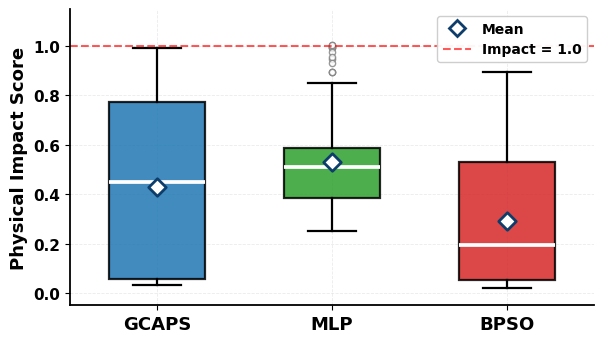

Saved: fig7_physical_impact_score.png
Saved: fig7_physical_impact_score.pdf


In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import warnings

warnings.filterwarnings("ignore")
%matplotlib inline

# ==========================================================
# USER SETTINGS
# ==========================================================
CSV_PATH = r"C:\Users\ISLAS2\Downloads\targeted_method_comparison_34bus.CSV"

OUTPUT_PNG = "fig7_physical_impact_score.png"
OUTPUT_PDF = "fig7_physical_impact_score.pdf"

# ==========================================================
# LOAD DATA
# ==========================================================
df = pd.read_csv(CSV_PATH)

METHODS = ["GRL", "MLP", "BPSO"]
LABELS = ["GCAPS", "MLP", "BPSO"]

COLORS = {
    "GRL": "#1f77b4",   # blue
    "MLP": "#2ca02c",   # green
    "BPSO": "#d62728"   # red
}

# Attacked scenarios only
atk = df[df["mode"] == "attacked_dynamic"].copy()

data = [
    atk[atk["method"] == m]["physical_impact_score"].dropna().values
    for m in METHODS
]

# ==========================================================
# STYLE
# ==========================================================
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 12,
    "axes.linewidth": 1.3,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "grid.linestyle": "--",
    "grid.linewidth": 0.6,
    "xtick.direction": "out",
    "ytick.direction": "out",
    "figure.facecolor": "white"
})

# ==========================================================
# FIGURE
# ==========================================================
fig, ax = plt.subplots(figsize=(6.2, 3.6))

bp = ax.boxplot(
    data,
    positions=[1, 2, 3],
    widths=0.55,
    patch_artist=True,
    showfliers=True,
    medianprops=dict(color="white", linewidth=2.7),
    whiskerprops=dict(color="black", linewidth=1.6),
    capprops=dict(color="black", linewidth=1.6),
    boxprops=dict(color="black", linewidth=1.6),
    flierprops=dict(
        marker="o",
        markerfacecolor="white",
        markeredgecolor="gray",
        markersize=4.5,
        alpha=0.8
    )
)

for patch, m in zip(bp["boxes"], METHODS):
    patch.set_facecolor(COLORS[m])
    patch.set_alpha(0.85)

# Mean diamond
mean_values = []
for i, m in enumerate(METHODS, start=1):
    vals = atk[atk["method"] == m]["physical_impact_score"].dropna()
    mean_val = vals.mean()
    mean_values.append(mean_val)

    ax.scatter(
        i,
        mean_val,
        marker="D",
        s=80,
        facecolor="white",
        edgecolor="#0d3d6b",
        linewidth=2.0,
        zorder=5
    )

# Impact reference line
ax.axhline(
    1.0,
    color="red",
    linestyle="--",
    linewidth=1.5,
    alpha=0.65
)

# ==========================================================
# LEGEND
# ==========================================================
legend_handles = [
    Line2D(
        [0], [0],
        marker="D",
        color="none",
        markerfacecolor="white",
        markeredgecolor="#0d3d6b",
        markeredgewidth=2,
        markersize=8,
        label="Mean"
    ),
    Line2D(
        [0], [0],
        color="red",
        linestyle="--",
        linewidth=1.5,
        alpha=0.65,
        label="Impact = 1.0"
    )
]

ax.legend(
    handles=legend_handles,
    loc="upper right",
    fontsize=10,
    framealpha=0.95,
    prop={"weight": "bold", "size": 10}
)

# ==========================================================
# AXES
# ==========================================================
ax.set_ylabel(
    "Physical Impact Score",
    fontsize=13,
    fontweight="bold"
)

ax.set_xticks([1, 2, 3])
ax.set_xticklabels(
    LABELS,
    fontsize=13,
    fontweight="bold"
)

ax.set_ylim(-0.05, 1.15)

for tick in ax.get_yticklabels():
    tick.set_fontsize(11)
    tick.set_fontweight("bold")

for spine in ax.spines.values():
    spine.set_linewidth(1.3)

plt.tight_layout()

# ==========================================================
# SAVE
# ==========================================================
fig.savefig(OUTPUT_PNG, dpi=600, bbox_inches="tight")
fig.savefig(OUTPUT_PDF, dpi=600, bbox_inches="tight")

plt.show()

print(f"Saved: {OUTPUT_PNG}")
print(f"Saved: {OUTPUT_PDF}")

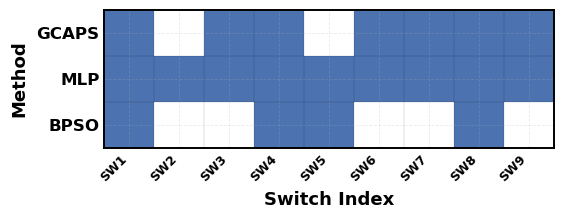

Saved: fig_switch_status_outage_only.pdf
Saved: fig_switch_status_outage_only.png


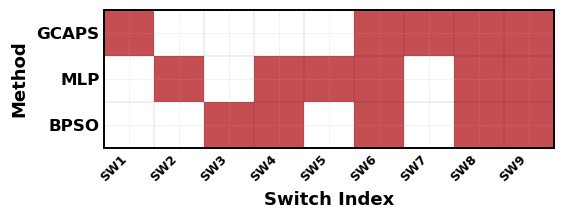

Saved: fig_switch_status_outage_fdia.pdf
Saved: fig_switch_status_outage_fdia.png


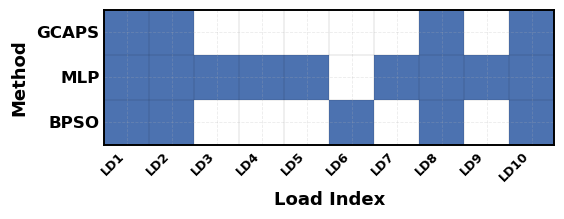

Saved: fig_load_shedding_status_outage_only.pdf
Saved: fig_load_shedding_status_outage_only.png


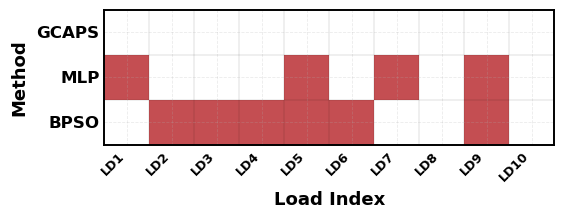

Saved: fig_load_shedding_status_outage_fdia.pdf
Saved: fig_load_shedding_status_outage_fdia.png


In [26]:
import pandas as pd
import numpy as np
import ast
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import warnings

warnings.filterwarnings("ignore")
%matplotlib inline

# ==========================================================
# USER SETTINGS
# ==========================================================
CSV_PATH = r"C:\Users\ISLAS2\Downloads\targeted_method_comparison_34bus.CSV"
SELECTED_HOUR = 12

# ==========================================================
# LOAD DATA
# ==========================================================
df = pd.read_csv(CSV_PATH)

df["method_plot"] = df["method"].replace({"GRL": "GCAPS"})

METHODS = ["GCAPS", "MLP", "BPSO"]

# ==========================================================
# PARSING FUNCTIONS
# ==========================================================
def parse_vector(x):
    if isinstance(x, str):
        x = ast.literal_eval(x)

    if isinstance(x, dict):
        x = list(x.values())

    out = []

    for v in x:
        if isinstance(v, str):
            v_clean = v.strip().lower()

            if v_clean in ["1", "on", "closed", "served", "connected", "energized", "true"]:
                out.append(1)
            elif v_clean in ["0", "off", "open", "shed", "disconnected", "deenergized", "false"]:
                out.append(0)
            else:
                out.append(float(v_clean))
        else:
            out.append(float(v))

    return out


def get_labels(x, prefix):
    if isinstance(x, str):
        x = ast.literal_eval(x)

    if isinstance(x, dict):
        return list(x.keys())

    return [f"{prefix}{i+1}" for i in range(len(x))]


def build_matrix(data, vector_col):
    rows = []
    labels = None

    for method in METHODS:
        row_df = data[data["method_plot"] == method]

        if row_df.empty:
            raise ValueError(f"No data found for method: {method}")

        raw = row_df.iloc[0][vector_col]
        vec = parse_vector(raw)
        rows.append(vec)

        if labels is None:
            labels = get_labels(raw, "x")

    return np.array(rows, dtype=float), labels


def short_labels(labels, prefix):
    return [f"{prefix}{i+1}" for i in range(len(labels))]


# ==========================================================
# PLOT FUNCTION
# ==========================================================
def plot_single_heatmap(
    vector_col,
    mode_name,
    output_file,
    x_prefix,
    x_axis_label,
    cmap_color
):
    df_hour = df[
        (df["hour"] == SELECTED_HOUR) &
        (df["mode"] == mode_name)
    ].copy()

    matrix, labels = build_matrix(df_hour, vector_col)
    plot_labels = short_labels(labels, x_prefix)

    cmap = ListedColormap(["white", cmap_color])

    fig, ax = plt.subplots(figsize=(5.8, 2.35))

    ax.imshow(
        matrix,
        aspect="auto",
        cmap=cmap,
        vmin=0,
        vmax=1
    )

    # ======================================================
    # AXES
    # ======================================================
    ax.set_yticks(np.arange(len(METHODS)))
    ax.set_yticklabels(
        METHODS,
        fontsize=12,
        fontweight="bold"
    )

    ax.set_xticks(np.arange(matrix.shape[1]))
    ax.set_xticklabels(
        plot_labels,
        rotation=45,
        ha="right",
        fontsize=9,
        fontweight="bold"
    )

    ax.set_xlabel(
        x_axis_label,
        fontsize=13,
        fontweight="bold",
        labelpad=5
    )

    ax.set_ylabel(
        "Method",
        fontsize=13,
        fontweight="bold",
        labelpad=6
    )

    ax.tick_params(axis="both", length=0)

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(1.4)
        spine.set_color("black")

    # cell grid lines
    ax.set_xticks(np.arange(-0.5, matrix.shape[1], 1), minor=True)
    ax.set_yticks(np.arange(-0.5, matrix.shape[0], 1), minor=True)
    ax.grid(which="minor", color="black", linestyle="-", linewidth=0.35)
    ax.tick_params(which="minor", bottom=False, left=False)

    plt.tight_layout()

    fig.savefig(output_file, dpi=600, bbox_inches="tight")
    fig.savefig(output_file.replace(".pdf", ".png"), dpi=600, bbox_inches="tight")

    plt.show()

    print(f"Saved: {output_file}")
    print(f"Saved: {output_file.replace('.pdf', '.png')}")


# ==========================================================
# FOUR SEPARATE FIGURES
# ==========================================================

# 1. Switch Status — Outage Only
plot_single_heatmap(
    vector_col="switch_vector",
    mode_name="clean_dynamic",
    output_file="fig_switch_status_outage_only.pdf",
    x_prefix="SW",
    x_axis_label="Switch Index",
    cmap_color="#4C72B0"
)

# 2. Switch Status — Outage with FDIA
plot_single_heatmap(
    vector_col="switch_vector",
    mode_name="attacked_dynamic",
    output_file="fig_switch_status_outage_fdia.pdf",
    x_prefix="SW",
    x_axis_label="Switch Index",
    cmap_color="#C44E52"
)

# 3. Load Shedding Status — Outage Only
plot_single_heatmap(
    vector_col="load_status",
    mode_name="clean_dynamic",
    output_file="fig_load_shedding_status_outage_only.pdf",
    x_prefix="LD",
    x_axis_label="Load Index",
    cmap_color="#4C72B0"
)

# 4. Load Shedding Status — Outage with FDIA
plot_single_heatmap(
    vector_col="load_status",
    mode_name="attacked_dynamic",
    output_file="fig_load_shedding_status_outage_fdia.pdf",
    x_prefix="LD",
    x_axis_label="Load Index",
    cmap_color="#C44E52"
)

In [30]:
import pandas as pd
import numpy as np
import ast
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import warnings

warnings.filterwarnings("ignore")
%matplotlib inline

CSV_PATH = r"C:\Users\ISLAS2\Downloads\targeted_method_comparison_34bus.CSV"
SELECTED_HOUR = 12

df = pd.read_csv(CSV_PATH)
df["method_plot"] = df["method"].replace({"GRL": "GCAPS"})

METHODS = ["GCAPS", "MLP", "BPSO"]


def parse_vector(x):
    if isinstance(x, str):
        x = ast.literal_eval(x)

    if isinstance(x, dict):
        x = list(x.values())

    out = []
    for v in x:
        if isinstance(v, str):
            v_clean = v.strip().lower()

            if v_clean in ["1", "on", "closed", "served", "connected", "energized", "true"]:
                out.append(1)
            elif v_clean in ["0", "off", "open", "shed", "disconnected", "deenergized", "false"]:
                out.append(0)
            else:
                out.append(float(v_clean))
        else:
            out.append(float(v))

    return out


def get_labels(x, prefix):
    if isinstance(x, str):
        x = ast.literal_eval(x)

    if isinstance(x, dict):
        return list(x.keys())

    return [f"{prefix}{i+1}" for i in range(len(x))]


def build_matrix(data, vector_col):
    rows = []
    labels = None

    for method in METHODS:
        row_df = data[data["method_plot"] == method]

        if row_df.empty:
            raise ValueError(f"No data found for method: {method}")

        raw = row_df.iloc[0][vector_col]
        rows.append(parse_vector(raw))

        if labels is None:
            labels = get_labels(raw, "x")

    return np.array(rows, dtype=float), labels


def short_labels(labels, prefix):
    return [f"{prefix}{i+1}" for i in range(len(labels))]


def plot_square_heatmap(
    vector_col,
    mode_name,
    output_file,
    x_prefix,
    x_axis_label,
    cmap_color
):
    data = df[
        (df["hour"] == SELECTED_HOUR) &
        (df["mode"] == mode_name)
    ].copy()

    matrix, labels = build_matrix(data, vector_col)
    plot_labels = short_labels(labels, x_prefix)

    cmap = ListedColormap(["white", cmap_color])

    fig, ax = plt.subplots(figsize=(3.2, 2.6))

    ax.imshow(
        matrix,
        aspect="auto",
        cmap=cmap,
        vmin=0,
        vmax=1
    )

    ax.set_yticks(np.arange(len(METHODS)))
    ax.set_yticklabels(
        METHODS,
        fontsize=8,
        fontweight="bold"
    )

    ax.set_xticks(np.arange(matrix.shape[1]))
    ax.set_xticklabels(
        plot_labels,
        rotation=90,
        ha="center",
        fontsize=6.5,
        fontweight="bold"
    )

    ax.set_xlabel(
        x_axis_label,
        fontsize=8,
        fontweight="bold",
        labelpad=2
    )

 ax.set_ylabel("")

    ax.tick_params(axis="both", length=0)

    ax.set_xticks(np.arange(-0.5, matrix.shape[1], 1), minor=True)
    ax.set_yticks(np.arange(-0.5, matrix.shape[0], 1), minor=True)

    ax.grid(
        which="minor",
        color="black",
        linestyle="-",
        linewidth=0.35
    )

    ax.tick_params(which="minor", bottom=False, left=False)

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(1.1)
        spine.set_color("black")

    plt.subplots_adjust(
    left=0.10,
    right=0.98,
    top=0.97,
    bottom=0.34
)

    fig.savefig(output_file, dpi=600, bbox_inches="tight")
    fig.savefig(output_file.replace(".pdf", ".png"), dpi=600, bbox_inches="tight")

    plt.show()

    print(f"Saved: {output_file}")
    print(f"Saved: {output_file.replace('.pdf', '.png')}")


plot_square_heatmap(
    vector_col="switch_vector",
    mode_name="clean_dynamic",
    output_file="fig_switch_status_outage_only.pdf",
    x_prefix="SW",
    x_axis_label="Switch Index",
    cmap_color="#4C72B0"
)

plot_square_heatmap(
    vector_col="switch_vector",
    mode_name="attacked_dynamic",
    output_file="fig_switch_status_outage_fdia.pdf",
    x_prefix="SW",
    x_axis_label="Switch Index",
    cmap_color="#C44E52"
)

plot_square_heatmap(
    vector_col="load_status",
    mode_name="clean_dynamic",
    output_file="fig_load_shedding_status_outage_only.pdf",
    x_prefix="LD",
    x_axis_label="Load Index",
    cmap_color="#4C72B0"
)

plot_square_heatmap(
    vector_col="load_status",
    mode_name="attacked_dynamic",
    output_file="fig_load_shedding_status_outage_fdia.pdf",
    x_prefix="LD",
    x_axis_label="Load Index",
    cmap_color="#C44E52"
)

IndentationError: unindent does not match any outer indentation level (<string>, line 128)

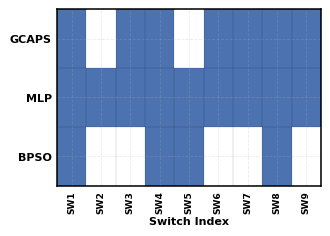

Saved: fig_switch_status_outage_only.pdf


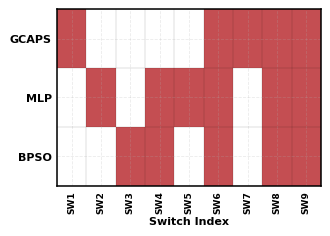

Saved: fig_switch_status_fdia.pdf


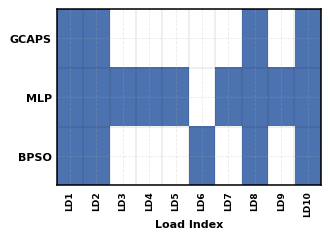

Saved: fig_load_status_outage_only.pdf


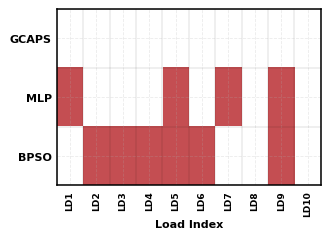

Saved: fig_load_status_fdia.pdf


In [35]:
import pandas as pd
import numpy as np
import ast
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import warnings

warnings.filterwarnings("ignore")
%matplotlib inline

# ==========================================================
# USER SETTINGS
# ==========================================================
CSV_PATH = r"C:\Users\ISLAS2\Downloads\targeted_method_comparison_34bus.CSV"
SELECTED_HOUR = 12

# ==========================================================
# LOAD DATA
# ==========================================================
df = pd.read_csv(CSV_PATH)

df["method_plot"] = df["method"].replace({"GRL": "GCAPS"})

METHODS = ["GCAPS", "MLP", "BPSO"]

# ==========================================================
# HELPERS
# ==========================================================
def parse_vector(x):

    if isinstance(x, str):
        x = ast.literal_eval(x)

    if isinstance(x, dict):
        x = list(x.values())

    out = []

    for v in x:

        if isinstance(v, str):

            v_clean = v.strip().lower()

            if v_clean in [
                "1", "on", "closed", "served",
                "connected", "energized", "true"
            ]:
                out.append(1)

            elif v_clean in [
                "0", "off", "open", "shed",
                "disconnected", "deenergized", "false"
            ]:
                out.append(0)

            else:
                out.append(float(v_clean))

        else:
            out.append(float(v))

    return out


def get_labels(x, prefix):

    if isinstance(x, str):
        x = ast.literal_eval(x)

    if isinstance(x, dict):
        return list(x.keys())

    return [f"{prefix}{i+1}" for i in range(len(x))


]


def build_matrix(data, vector_col):

    rows = []
    labels = None

    for method in METHODS:

        row_df = data[data["method_plot"] == method]

        if row_df.empty:
            raise ValueError(f"No data found for method: {method}")

        raw = row_df.iloc[0][vector_col]

        vec = parse_vector(raw)

        rows.append(vec)

        if labels is None:
            labels = get_labels(raw, "x")

    return np.array(rows, dtype=float), labels


def short_labels(labels, prefix):
    return [f"{prefix}{i+1}" for i in range(len(labels))]


# ==========================================================
# MAIN PLOT FUNCTION
# ==========================================================
def plot_square_heatmap(
    vector_col,
    mode_name,
    output_file,
    x_prefix,
    x_axis_label,
    cmap_color
):

    data = df[
        (df["hour"] == SELECTED_HOUR) &
        (df["mode"] == mode_name)
    ].copy()

    matrix, labels = build_matrix(data, vector_col)

    plot_labels = short_labels(labels, x_prefix)

    cmap = ListedColormap([
        "white",
        cmap_color
    ])

    fig, ax = plt.subplots(
        figsize=(3.0, 2.8)
    )

    ax.imshow(
        matrix,
        aspect="auto",
        cmap=cmap,
        vmin=0,
        vmax=1
    )

    # ------------------------------------------------------
    # Y LABELS ONLY (NO "METHOD" AXIS LABEL)
    # ------------------------------------------------------
    ax.set_yticks(np.arange(len(METHODS)))

    ax.set_yticklabels(
        METHODS,
        fontsize=8,
        fontweight="bold"
    )

    # ------------------------------------------------------
    # X LABELS
    # ------------------------------------------------------
    ax.set_xticks(np.arange(matrix.shape[1]))

    ax.set_xticklabels(
        plot_labels,
        rotation=90,
        ha="center",
        fontsize=6.5,
        fontweight="bold"
    )

    ax.set_xlabel(
        x_axis_label,
        fontsize=8,
        fontweight="bold",
        labelpad=2
    )

    ax.set_ylabel("")

    ax.tick_params(
        axis="both",
        length=0
    )

    # ------------------------------------------------------
    # CELL GRID
    # ------------------------------------------------------
    ax.set_xticks(
        np.arange(-0.5, matrix.shape[1], 1),
        minor=True
    )

    ax.set_yticks(
        np.arange(-0.5, matrix.shape[0], 1),
        minor=True
    )

    ax.grid(
        which="minor",
        color="black",
        linestyle="-",
        linewidth=0.35
    )

    ax.tick_params(
        which="minor",
        bottom=False,
        left=False
    )

    # ------------------------------------------------------
    # BORDER
    # ------------------------------------------------------
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(1.1)
        spine.set_color("black")

    plt.subplots_adjust(
        left=0.10,
        right=0.98,
        top=0.97,
        bottom=0.34
    )

    fig.savefig(
        output_file,
        dpi=600,
        bbox_inches="tight"
    )

    fig.savefig(
        output_file.replace(".pdf", ".png"),
        dpi=600,
        bbox_inches="tight"
    )

    plt.show()

    print("Saved:", output_file)


# ==========================================================
# FIGURE 1
# Switch Status — Outage Only
# ==========================================================
plot_square_heatmap(
    vector_col="switch_vector",
    mode_name="clean_dynamic",
    output_file="fig_switch_status_outage_only.pdf",
    x_prefix="SW",
    x_axis_label="Switch Index",
    cmap_color="#4C72B0"
)

# ==========================================================
# FIGURE 2
# Switch Status — FDIA
# ==========================================================
plot_square_heatmap(
    vector_col="switch_vector",
    mode_name="attacked_dynamic",
    output_file="fig_switch_status_fdia.pdf",
    x_prefix="SW",
    x_axis_label="Switch Index",
    cmap_color="#C44E52"
)

# ==========================================================
# FIGURE 3
# Load Shedding — Outage Only
# ==========================================================
plot_square_heatmap(
    vector_col="load_status",
    mode_name="clean_dynamic",
    output_file="fig_load_status_outage_only.pdf",
    x_prefix="LD",
    x_axis_label="Load Index",
    cmap_color="#4C72B0"
)

# ==========================================================
# FIGURE 4
# Load Shedding — FDIA
# ==========================================================
plot_square_heatmap(
    vector_col="load_status",
    mode_name="attacked_dynamic",
    output_file="fig_load_status_fdia.pdf",
    x_prefix="LD",
    x_axis_label="Load Index",
    cmap_color="#C44E52"
)

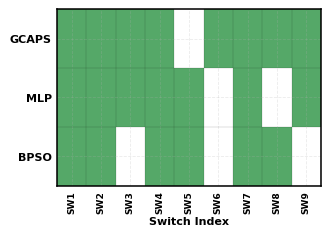

Saved: fig_switch_status_after_mitigation.pdf


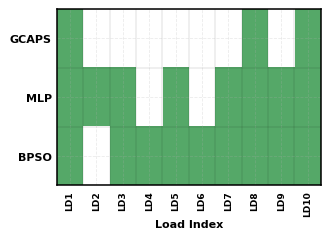

Saved: fig_load_status_after_mitigation.pdf


In [36]:
import pandas as pd
import numpy as np
import ast
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import warnings

warnings.filterwarnings("ignore")
%matplotlib inline

# ==========================================================
# USER SETTINGS
# ==========================================================
CSV_PATH = r"C:\Users\ISLAS2\Downloads\gae_mitigation_comparison_34bus.csv"
SELECTED_HOUR = 12

# ==========================================================
# LOAD DATA
# ==========================================================
df = pd.read_csv(CSV_PATH)

if "paper_method_label" in df.columns:
    df["method_plot"] = df["paper_method_label"].replace({"GRL": "GCAPS"})
else:
    df["method_plot"] = df["method"].replace({"GRL": "GCAPS"})

METHODS = ["GCAPS", "MLP", "BPSO"]

# ==========================================================
# HELPERS
# ==========================================================
def parse_vector(x):

    if isinstance(x, str):
        x = ast.literal_eval(x)

    if isinstance(x, dict):
        x = list(x.values())

    out = []

    for v in x:
        if isinstance(v, str):
            v_clean = v.strip().lower()

            if v_clean in ["1", "on", "closed", "served", "connected", "energized", "true"]:
                out.append(1)

            elif v_clean in ["0", "off", "open", "shed", "disconnected", "deenergized", "false"]:
                out.append(0)

            else:
                out.append(float(v_clean))
        else:
            out.append(float(v))

    return out


def get_labels(x, prefix):

    if isinstance(x, str):
        x = ast.literal_eval(x)

    if isinstance(x, dict):
        return list(x.keys())

    return [f"{prefix}{i+1}" for i in range(len(x))]


def build_matrix(data, vector_col):

    rows = []
    labels = None

    for method in METHODS:

        row_df = data[data["method_plot"] == method]

        if row_df.empty:
            raise ValueError(f"No data found for method: {method}")

        raw = row_df.iloc[0][vector_col]
        vec = parse_vector(raw)

        rows.append(vec)

        if labels is None:
            labels = get_labels(raw, "x")

    return np.array(rows, dtype=float), labels


def short_labels(labels, prefix):
    return [f"{prefix}{i+1}" for i in range(len(labels))]


# ==========================================================
# MAIN PLOT FUNCTION
# ==========================================================
def plot_square_heatmap(
    vector_col,
    mode_name,
    output_file,
    x_prefix,
    x_axis_label,
    cmap_color
):

    data = df[
        (df["hour"] == SELECTED_HOUR) &
        (df["mode"] == mode_name)
    ].copy()

    matrix, labels = build_matrix(data, vector_col)
    plot_labels = short_labels(labels, x_prefix)

    cmap = ListedColormap(["white", cmap_color])

    fig, ax = plt.subplots(figsize=(3.0, 2.8))

    ax.imshow(
        matrix,
        aspect="auto",
        cmap=cmap,
        vmin=0,
        vmax=1
    )

    ax.set_yticks(np.arange(len(METHODS)))
    ax.set_yticklabels(METHODS, fontsize=8, fontweight="bold")

    ax.set_xticks(np.arange(matrix.shape[1]))
    ax.set_xticklabels(
        plot_labels,
        rotation=90,
        ha="center",
        fontsize=6.5,
        fontweight="bold"
    )

    ax.set_xlabel(
        x_axis_label,
        fontsize=8,
        fontweight="bold",
        labelpad=2
    )

    ax.set_ylabel("")
    ax.tick_params(axis="both", length=0)

    ax.set_xticks(np.arange(-0.5, matrix.shape[1], 1), minor=True)
    ax.set_yticks(np.arange(-0.5, matrix.shape[0], 1), minor=True)

    ax.grid(
        which="minor",
        color="black",
        linestyle="-",
        linewidth=0.35
    )

    ax.tick_params(which="minor", bottom=False, left=False)

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(1.1)
        spine.set_color("black")

    plt.subplots_adjust(
        left=0.10,
        right=0.98,
        top=0.97,
        bottom=0.34
    )

    fig.savefig(output_file, dpi=600, bbox_inches="tight")
    fig.savefig(output_file.replace(".pdf", ".png"), dpi=600, bbox_inches="tight")

    plt.show()

    print("Saved:", output_file)


# ==========================================================
# FIGURE 1
# Switch Status — After Mitigation
# ==========================================================
plot_square_heatmap(
    vector_col="switch_vector",
    mode_name="mitigated_dynamic",
    output_file="fig_switch_status_after_mitigation.pdf",
    x_prefix="SW",
    x_axis_label="Switch Index",
    cmap_color="#55A868"
)

# ==========================================================
# FIGURE 2
# Load Status — After Mitigation
# ==========================================================
plot_square_heatmap(
    vector_col="load_status",
    mode_name="mitigated_dynamic",
    output_file="fig_load_status_after_mitigation.pdf",
    x_prefix="LD",
    x_axis_label="Load Index",
    cmap_color="#55A868"
)

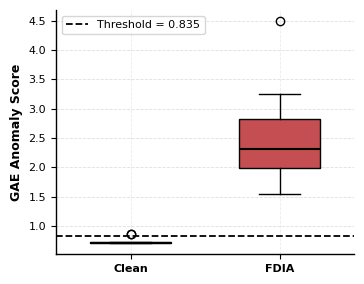

Threshold = 0.8353686902909511
Clean samples = 15
Attack samples = 15


In [40]:
import pandas as pd
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings("ignore")

# ==========================================================
# LOAD DATA
# ==========================================================
CSV_PATH = r"C:\Users\ISLAS2\Downloads\gae_detection_cases_34bus.csv"

df = pd.read_csv(CSV_PATH)

# ==========================================================
# CLEAN VS ATTACK
# ==========================================================
clean_scores = df[
    df["mode"] == "clean_dynamic"
]["gae_score"]

attack_scores = df[
    df["mode"] == "attacked_dynamic"
]["gae_score"]

threshold = df["gae_threshold"].iloc[0]

# ==========================================================
# PLOT
# ==========================================================
fig, ax = plt.subplots(figsize=(3.8, 3.0))

bp = ax.boxplot(
    [clean_scores, attack_scores],
    labels=["Clean", "FDIA"],
    patch_artist=True,
    widths=0.55
)

# Colors
bp["boxes"][0].set_facecolor("#4C72B0")
bp["boxes"][1].set_facecolor("#C44E52")

for median in bp["medians"]:
    median.set_color("black")
    median.set_linewidth(1.5)

# Detection threshold
ax.axhline(
    threshold,
    color="black",
    linestyle="--",
    linewidth=1.3,
    label=f"Threshold = {threshold:.3f}"
)

ax.legend(
    fontsize=8,
    loc="upper left"
)

# Formatting
ax.set_ylabel(
    "GAE Anomaly Score",
    fontsize=9,
    fontweight="bold"
)

ax.tick_params(
    axis="both",
    labelsize=8
)

for tick in ax.get_xticklabels():
    tick.set_fontweight("bold")

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.4
)

for spine in ax.spines.values():
    spine.set_linewidth(1.0)

plt.tight_layout()

# ==========================================================
# SAVE
# ==========================================================
plt.savefig(
    "fig_gae_anomaly_score_distribution.pdf",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "fig_gae_anomaly_score_distribution.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

print("Threshold =", threshold)
print("Clean samples =", len(clean_scores))
print("Attack samples =", len(attack_scores))

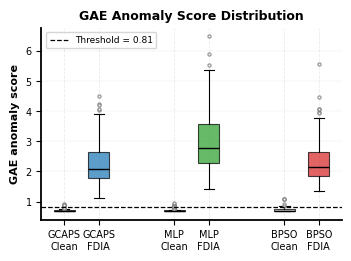

In [46]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

csv_path = r"C:\Users\ISLAS2\Downloads\expanded_gae_detection_cases_34bus.csv"
df = pd.read_csv(csv_path)

method_labels = {
    "GRL": "GCAPS",
    "MLP": "MLP",
    "BPSO": "BPSO"
}

colors = {
    "GRL": "#1f77b4",
    "MLP": "#2ca02c",
    "BPSO": "#d62728"
}

threshold = df["gae_threshold"].mean()

data = []
positions = []
labels = []
box_colors = []

for i, method in enumerate(["GRL", "MLP", "BPSO"]):
    clean_scores = df[
        (df["target_method"] == method) &
        (df["expected_attack"] == 0)
    ]["gae_score"]

    attack_scores = df[
        (df["target_method"] == method) &
        (df["expected_attack"] == 1)
    ]["gae_score"]

    data.extend([clean_scores, attack_scores])
    positions.extend([i * 2.4 + 1, i * 2.4 + 1.75])
    labels.extend([
        f"{method_labels[method]}\nClean",
        f"{method_labels[method]}\nFDIA"
    ])
    box_colors.extend(["#bdbdbd", colors[method]])

fig, ax = plt.subplots(figsize=(3.45, 2.55))

box = ax.boxplot(
    data,
    positions=positions,
    widths=0.45,
    patch_artist=True,
    showfliers=True,
    flierprops=dict(
        marker="o",
        markersize=2.2,
        markerfacecolor="white",
        markeredgecolor="gray",
        alpha=0.75
    )
)

for patch, color in zip(box["boxes"], box_colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.72)
    patch.set_linewidth(0.8)

for median in box["medians"]:
    median.set_color("black")
    median.set_linewidth(1.0)

for whisker in box["whiskers"]:
    whisker.set_linewidth(0.8)

for cap in box["caps"]:
    cap.set_linewidth(0.8)

ax.axhline(
    threshold,
    color="black",
    linestyle="--",
    linewidth=0.9,
    label=f"Threshold = {threshold:.2f}"
)

ax.set_xticks(positions)
ax.set_xticklabels(labels, fontsize=7)
ax.set_ylabel(
    "GAE Anomaly Score",
    fontsize=8,
    fontweight="bold",
    color="black"
)

ax.tick_params(axis="y", labelsize=7)
ax.grid(True, axis="y", linestyle="--", linewidth=0.35, alpha=0.35)

ax.legend(frameon=True, fontsize=6.5, loc="upper left")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout(pad=0.4)
plt.show()
fig.savefig(
    r"C:\Users\ISLAS2\Downloads\fig_gae_anomaly_score_boxplot_34bus_single_column.png",
    dpi=600,
    bbox_inches="tight"
)

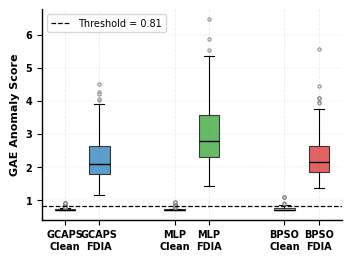

In [47]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# ==========================================================
# LOAD DATA
# ==========================================================
csv_path = r"C:\Users\ISLAS2\Downloads\expanded_gae_detection_cases_34bus.csv"
df = pd.read_csv(csv_path)

# ==========================================================
# SETTINGS
# ==========================================================
method_labels = {
    "GRL": "GCAPS",
    "MLP": "MLP",
    "BPSO": "BPSO"
}

colors = {
    "GRL": "#1f77b4",
    "MLP": "#2ca02c",
    "BPSO": "#d62728"
}

threshold = df["gae_threshold"].mean()

# ==========================================================
# PREPARE DATA
# ==========================================================
data = []
positions = []
labels = []
box_colors = []

for i, method in enumerate(["GRL", "MLP", "BPSO"]):

    clean_scores = df[
        (df["target_method"] == method) &
        (df["expected_attack"] == 0)
    ]["gae_score"]

    attack_scores = df[
        (df["target_method"] == method) &
        (df["expected_attack"] == 1)
    ]["gae_score"]

    data.extend([clean_scores, attack_scores])

    positions.extend([
        i * 2.4 + 1,
        i * 2.4 + 1.75
    ])

    labels.extend([
        f"{method_labels[method]}\nClean",
        f"{method_labels[method]}\nFDIA"
    ])

    box_colors.extend([
        "#bdbdbd",
        colors[method]
    ])

# ==========================================================
# PLOT
# ==========================================================
fig, ax = plt.subplots(figsize=(3.45, 2.55))

box = ax.boxplot(
    data,
    positions=positions,
    widths=0.45,
    patch_artist=True,
    showfliers=True,
    flierprops=dict(
        marker="o",
        markersize=2.2,
        markerfacecolor="white",
        markeredgecolor="gray",
        alpha=0.75
    )
)

# ==========================================================
# BOX COLORS
# ==========================================================
for patch, color in zip(box["boxes"], box_colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.72)
    patch.set_linewidth(0.8)

for median in box["medians"]:
    median.set_color("black")
    median.set_linewidth(1.0)

for whisker in box["whiskers"]:
    whisker.set_linewidth(0.8)

for cap in box["caps"]:
    cap.set_linewidth(0.8)

# ==========================================================
# THRESHOLD
# ==========================================================
ax.axhline(
    threshold,
    color="black",
    linestyle="--",
    linewidth=0.9,
    label=f"Threshold = {threshold:.2f}"
)

# ==========================================================
# AXIS LABELS
# ==========================================================
ax.set_ylabel(
    "GAE Anomaly Score",
    fontsize=8,
    fontweight="bold",
    color="black"
)

# Optional:
# ax.set_xlabel(
#     "Operating Condition",
#     fontsize=8,
#     fontweight="bold",
#     color="black"
# )

# ==========================================================
# X-TICKS
# ==========================================================
ax.set_xticks(positions)

ax.set_xticklabels(
    labels,
    fontsize=7,
    fontweight="bold",
    color="black"
)

# ==========================================================
# Y-TICKS
# ==========================================================
ax.tick_params(
    axis="y",
    labelsize=7,
    colors="black"
)

for tick in ax.get_yticklabels():
    tick.set_fontweight("bold")

# ==========================================================
# GRID
# ==========================================================
ax.grid(
    True,
    axis="y",
    linestyle="--",
    linewidth=0.35,
    alpha=0.35
)

# ==========================================================
# LEGEND
# ==========================================================
ax.legend(
    frameon=True,
    fontsize=7,
    loc="upper left"
)

# ==========================================================
# SPINES
# ==========================================================
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.spines["left"].set_linewidth(1.0)
ax.spines["bottom"].set_linewidth(1.0)

# ==========================================================
# SAVE
# ==========================================================
plt.tight_layout(pad=0.4)

fig.savefig(
    r"C:\Users\ISLAS2\Downloads\fig_gae_anomaly_score_boxplot_34bus_single_column.pdf",
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    r"C:\Users\ISLAS2\Downloads\fig_gae_anomaly_score_boxplot_34bus_single_column.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

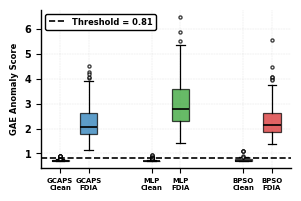

Saved:
fig_gae_anomaly_score_boxplot_34bus_single_column.pdf
fig_gae_anomaly_score_boxplot_34bus_single_column.png


In [59]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# ==========================================================
# LOAD DATA
# ==========================================================
csv_path = r"C:\Users\ISLAS2\Downloads\expanded_gae_detection_cases_34bus.csv"
df = pd.read_csv(csv_path)

# ==========================================================
# GLOBAL STYLE
# ==========================================================
plt.rcParams["text.color"] = "black"
plt.rcParams["axes.labelcolor"] = "black"
plt.rcParams["xtick.color"] = "black"
plt.rcParams["ytick.color"] = "black"

# ==========================================================
# SETTINGS
# ==========================================================
method_labels = {
    "GRL": "GCAPS",
    "MLP": "MLP",
    "BPSO": "BPSO"
}

colors = {
    "GRL": "#1f77b4",
    "MLP": "#2ca02c",
    "BPSO": "#d62728"
}

threshold = df["gae_threshold"].mean()

# ==========================================================
# PREPARE DATA
# ==========================================================
data = []
positions = []
labels = []
box_colors = []

for i, method in enumerate(["GRL", "MLP", "BPSO"]):

    clean_scores = df[
        (df["target_method"] == method) &
        (df["expected_attack"] == 0)
    ]["gae_score"]

    attack_scores = df[
        (df["target_method"] == method) &
        (df["expected_attack"] == 1)
    ]["gae_score"]

    data.extend([clean_scores, attack_scores])

    positions.extend([
        i * 2.4 + 1,
        i * 2.4 + 1.75
    ])

    labels.extend([
        f"{method_labels[method]}\nClean",
        f"{method_labels[method]}\nFDIA"
    ])

    box_colors.extend([
        "#bdbdbd",
        colors[method]
    ])

# ==========================================================
# CREATE FIGURE
# ==========================================================
#fig, ax = plt.subplots(figsize=(3.45, 2.55))
fig, ax = plt.subplots(figsize=(2.90, 1.90))
box = ax.boxplot(
    data,
    positions=positions,
    widths=0.45,
    patch_artist=True,
    showfliers=True,
    flierprops=dict(
        marker="o",
        markersize=2.2,
        markerfacecolor="white",
        markeredgecolor="black",
        alpha=0.75
    )
)

# ==========================================================
# BOX FORMATTING
# ==========================================================
for patch, color in zip(box["boxes"], box_colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.72)
    patch.set_edgecolor("black")
    patch.set_linewidth(0.9)

for median in box["medians"]:
    median.set_color("black")
    median.set_linewidth(1.2)

for whisker in box["whiskers"]:
    whisker.set_color("black")
    whisker.set_linewidth(0.9)

for cap in box["caps"]:
    cap.set_color("black")
    cap.set_linewidth(0.9)

# ==========================================================
# THRESHOLD LINE
# ==========================================================
ax.axhline(
    threshold,
    color="black",
    linestyle="--",
    linewidth=1.2,
    label=f"Threshold = {threshold:.2f}"
)

# ==========================================================
# AXES LABELS
# ==========================================================
ax.set_ylabel(
    "GAE Anomaly Score",
    fontsize=6,
    fontweight="bold",
    color="black"
)

# ==========================================================
# X-TICKS
# ==========================================================
ax.set_xticks(positions)

ax.set_xticklabels(
    labels,
    fontsize=5,
    fontweight="bold",
    color="black"
)

# ==========================================================
# Y-TICKS
# ==========================================================
ax.tick_params(
    axis="y",
    labelsize=7,
    colors="black"
)

for tick in ax.get_yticklabels():
    tick.set_fontweight("bold")

# ==========================================================
# GRID
# ==========================================================
ax.grid(
    True,
    axis="y",
    linestyle="--",
    linewidth=0.35,
    alpha=0.35
)

# ==========================================================
# LEGEND
# ==========================================================
leg = ax.legend(
    frameon=True,
    fontsize=6,
    loc="upper left",
    facecolor="white",
    edgecolor="black",
    framealpha=1.0
)

for text in leg.get_texts():
    text.set_color("black")
    text.set_fontweight("bold")

# ==========================================================
# SPINES
# ==========================================================
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.spines["left"].set_color("black")
ax.spines["bottom"].set_color("black")

ax.spines["left"].set_linewidth(1.0)
ax.spines["bottom"].set_linewidth(1.0)

# ==========================================================
# LAYOUT
# ==========================================================
plt.tight_layout(pad=0.4)

# ==========================================================
# SAVE
# ==========================================================
fig.savefig(
    r"C:\Users\ISLAS2\Downloads\fig_gae_anomaly_score_boxplot_34bus_single_column.pdf",
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    r"C:\Users\ISLAS2\Downloads\fig_gae_anomaly_score_boxplot_34bus_single_column.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

print("Saved:")
print("fig_gae_anomaly_score_boxplot_34bus_single_column.pdf")
print("fig_gae_anomaly_score_boxplot_34bus_single_column.png")